# Task 3 – Combine & Improve: Hybrid Retrieval with Groundedness Verification

**Project 10 · Open-Domain Question Answering: From Lexical Retrieval to RAG**
**Dataset:** [`rag-datasets/rag-mini-wikipedia`](https://huggingface.co/datasets/rag-datasets/rag-mini-wikipedia)
**Group:** 28  
**Name:**  Nihar Ranjan Das  
**Roll.No:** 26AI60R20

### Objective
Combine the two retrieval signals of Tasks 1 and 2 into one retriever, and reuse Task 1's lexical-overlap idea to check whether Task 2's generated answers are supported by the retrieved evidence.

### What this notebook does
1. **Hybrid retrieval:** fuse the BM25 ranking (Task 1) and the dense ranking (Task 2) with **Reciprocal Rank Fusion** (constant 60), then answer with the **same LLM, prompt and decoding as Task 2** using the hybrid top-5.
2. **Groundedness check:** compute the lexical overlap between each Task 2 answer and the passages it was generated from, and flag (or abstain on) low-overlap answers as likely ungrounded.
3. **Evaluation:** EM, F1 and Recall@k of the hybrid system vs Task 1 and Task 2, the fraction of correct answers with high overlap and of incorrect answers with low overlap, and the accuracy of the groundedness check.

### How to run
`Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all` (about 5 minutes).
- **Inputs:** `task1_results.json` and `task2_results.json`. They are read from the output folder; with `USE_DRIVE = False` you are asked to upload them. Both files must come from the current Task 1 and Task 2 notebooks; Section 4 checks this.
- **Outputs:** `task3_results.json`, `task3_hybrid_generation_cache.json` and three plots: `task3_recall_compare.png`, `task3_overlap_hist.png` and `task3_threshold_sweep.png`.

### Contents
1. Setup
2. Loading the data
3. Evaluation helpers
4. Loading the Task 1 and Task 2 results
5. Hybrid retrieval with Reciprocal Rank Fusion
6. Answering with the hybrid top-5
7. Comparison: Task 1 vs Task 2 vs Task 3
8. Groundedness check
9. The check on the hybrid answers, and examples
10. Saving the results
11. Significance tests and further analysis
12. Discussion
13. References

## 1. Setup

| Setting | Value | Meaning |
|---|---|---|
| `RRF_C` | 60 | Reciprocal Rank Fusion constant (as required by the brief) |
| `TOP_K` | 5 | passages given to the LLM, as in Task 2 |
| `KS`, `KEEP_N` | 1, 3, 5, 10 · 100 | Recall@k cut-offs · length of the saved fused ranking |
| `THRESH` | 0.5 | overlap ≥ 0.5 counts as grounded; below it the answer is flagged |
| `CORRECT_F1` | 0.5 | an answer counts as correct if its token F1 is at least 0.5 |
| `DATASET_REVISION` | `1f9f3b5…` | fixed dataset version, identical in all notebooks |

The model name, prompt, token limits and batch size are not set here: they are read from `task2_results.json` in Section 4, so the generation settings are guaranteed to be identical to Task 2's.

With `USE_DRIVE = False`, the Colab `outputs/` folder is temporary, so download the result files at the end.

In [1]:
%pip install -q datasets "transformers>=4.56" accelerate scikit-learn

import os, re, sys, json, string, collections, random, time, unicodedata, hashlib
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

random.seed(42); np.random.seed(42)          # reproducibility

USE_DRIVE = False          # False = no Google Drive: upload the JSON files when asked, and download the
                           # results at the end (the Colab runtime's outputs/ folder is temporary)
try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:        # running locally instead of Colab
    IN_COLAB = False
OUT = 'outputs'
if IN_COLAB and USE_DRIVE:
    try:
        drive.mount('/content/drive')
        OUT = '/content/drive/MyDrive/NLP_Project_2/outputs'
    except Exception as e:                   # e.g. authorisation declined or timed out
        print('Google Drive not mounted, using local outputs/ instead:', e)
os.makedirs(OUT, exist_ok=True)
print('Reading/saving results in', OUT)

# ---- Settings required by the brief ----
RRF_C = 60                 # Reciprocal Rank Fusion constant
TOP_K = 5                  # passages given to the LLM (same as Task 2)
KS = [1, 3, 5, 10]         # Recall@k values to report
KEEP_N = 100               # length of the fused ranking that is saved
DATASET_REVISION = '1f9f3b53fbc5995b85aab8e993504ad42c5f16f6'   # pinned dataset version (same in all notebooks)

# ---- Groundedness check ----
THRESH = 0.5               # overlap >= THRESH counts as 'grounded'; below it is flagged
CORRECT_F1 = 0.5           # an answer counts as 'correct' if token F1 >= 0.5

# ---- Convenience settings ----  (BATCH_SIZE is read from task2_results.json in Section 4)
QUICK_TEST = False         # True = run on the first 40 questions only (to check the code works)

Reading/saving results in outputs


## 2. Loading the data
We load the same 3,200 passages and 918 questions as in Tasks 1 and 2, with the same encoding repair, so all three tasks see exactly the same text.

In [2]:
from datasets import load_dataset

corpus = load_dataset('rag-datasets/rag-mini-wikipedia', 'text-corpus', revision=DATASET_REVISION)
qa     = load_dataset('rag-datasets/rag-mini-wikipedia', 'question-answer', revision=DATASET_REVISION)

def fix_mojibake(s):
    # the dataset has UTF-8 text decoded as Latin-1, e.g. 'Lincolnâ\x80\x99s' instead of 'Lincoln’s'
    try:
        return s.encode('latin-1').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s                             # already clean - keep as is

passages    = [fix_mojibake(str(p)) for p in corpus['passages']['passage']]
passage_ids = list(corpus['passages']['id'])  # saved with the rankings, which are list positions
questions   = [fix_mojibake(str(q)) for q in qa['test']['question']]
answers     = [fix_mojibake(str(a)) for a in qa['test']['answer']]
N_ALL = len(questions)                     # 918 - used to check the saved files
if QUICK_TEST:
    questions, answers = questions[:40], answers[:40]

print(len(passages), 'passages |', len(questions), 'questions')
print('Example Q:', questions[0], '->', answers[0])

README.md:   0%|          | 0.00/719 [00:00<?, ?B/s]

data/passages.parquet/part.0.parquet: reconstructing file:   0%|          |  0.00B /  797kB            

data/passages.parquet/part.0.parquet: downloading bytes:           |  0.00B            

Generating passages split: 0 examples [00:00, ? examples/s]

data/test.parquet/part.0.parquet: reconstructing file:   0%|          |  0.00B / 54.4kB            

data/test.parquet/part.0.parquet: downloading bytes:           |  0.00B            

Generating test split: 0 examples [00:00, ? examples/s]

3200 passages | 918 questions
Example Q: Was Abraham Lincoln the sixteenth President of the United States? -> yes


## 3. Evaluation helpers
The first part of the cell is the same helper code as in Tasks 1 and 2. Three additions are specific to this notebook:
- the factual (`keep`) and yes/no (`yesno`) question subsets;
- `is_yes_no_prediction`, which recognises an answer that is *exactly* "yes" or "no". The gold-answer rule would also match a prediction such as *"No information provided."*, which must not be excluded from the groundedness check;
- `first_word`, used for yes/no accuracy, i.e. whether the yes/no part of the answer agrees with the gold answer.

In [3]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOP

# every Unicode punctuation / symbol character (string.punctuation plus ’ – “ ” © ° ...), built once
PUNCT_TABLE = dict.fromkeys(i for i in range(sys.maxunicode + 1)
                            if unicodedata.category(chr(i))[0] in 'PS')

def normalize_answer(s):
    # SQuAD-style: lowercase, drop punctuation, drop articles (a/an/the), squash spaces
    s = str(s).lower().translate(PUNCT_TABLE)
    s = re.sub(r'\b(a|an|the)\b', ' ', s)
    return ' '.join(s.split())

def exact_match(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))

def f1_score(pred, gold):
    p, g = normalize_answer(pred).split(), normalize_answer(gold).split()
    if len(p) == 0 or len(g) == 0:
        return float(p == g)
    same = sum((collections.Counter(p) & collections.Counter(g)).values())
    if same == 0:
        return 0.0
    precision, recall = same / len(p), same / len(g)
    return 2 * precision * recall / (precision + recall)

norm_passages = [f' {normalize_answer(p)} ' for p in passages]   # normalised once, reused below

def answer_in_passage(gold, passage):
    # True if the normalised gold answer appears as whole words inside the passage
    g = normalize_answer(gold)
    return len(g) > 0 and f' {g} ' in f' {normalize_answer(passage)} '

def first_hit_rank(ids, gold):
    # 1-based rank of the first passage in ids that contains the gold answer (inf if none)
    g = normalize_answer(gold)
    if not g:
        return np.inf
    return next((r for r, pid in enumerate(ids, 1) if f' {g} ' in norm_passages[pid]), np.inf)

def recall_at_k(ranked_lists, golds, k):
    # ranked_lists[i] = passage positions for question i, best first
    return float(np.mean([first_hit_rank(ids[:k], g) <= k for ids, g in zip(ranked_lists, golds)]))

def content_words(text):
    # normalised words that are NOT stop words (used for overlap heuristics)
    return {w for w in normalize_answer(text).split() if w not in STOP}

def is_yes_no(ans):
    # gold answer is a yes/no answer: 'yes', 'No!', and also 'Yes, they do.' / 'No, it contributed ...'
    return normalize_answer(ans).split()[:1] in (['yes'], ['no'])

def evaluate(preds, ranked, golds, name):
    row = {'System': name, 'N': len(golds),
           'EM': np.mean([exact_match(p, g) for p, g in zip(preds, golds)]),
           'F1': np.mean([f1_score(p, g) for p, g in zip(preds, golds)])}
    first = np.array([first_hit_rank(ids[:max(KS)], g) for ids, g in zip(ranked, golds)])  # once
    for k in KS:
        row[f'R@{k}'] = float(np.mean(first <= k))
    return row

# --- sanity test: should print 1.0  0.667  True  True
print(exact_match('The Eiffel Tower!', 'eiffel tower'),
      round(f1_score('Paris 1889', '1889'), 3),
      answer_in_passage('1889', 'It was built in 1889.'),
      exact_match('Lincoln’s', "Lincoln's"))

# --- used only in Notebook 3
sub = lambda xs, idx: [xs[i] for i in idx]
keep  = [i for i, a in enumerate(answers) if not is_yes_no(a)]     # factual questions (gold rule)
yesno = [i for i, a in enumerate(answers) if is_yes_no(a)]

def is_yes_no_prediction(pred):
    # a PREDICTION that is exactly yes/no; the gold rule above would also catch 'No information provided.'
    return normalize_answer(pred) in {'yes', 'no'}

first_word = lambda s: normalize_answer(s).split()[:1]            # yes/no accuracy: does yes vs no agree?

1.0 0.667 True 1.0


## 4. Loading the Task 1 and Task 2 results
We look for the two files in the output folder, `outputs/` and `/content/`. In Colab without Drive you are asked to upload them; a renamed copy such as *"task1_results (1).json"* is also accepted.

Before using them, we check that:
- both files come from runs with the same dataset version;
- both use the same passage order as this notebook.

Otherwise the rankings would point at different passages, so the cell stops with an explanation. The LLM settings (model, system prompt, token limits, batch size) are taken from `task2_results.json`.

In [4]:
def find_result(name):
    for folder in [OUT, 'outputs', '.', '/content', '/content/outputs']:
        path = os.path.join(folder, name)
        if os.path.exists(path):
            return path
    if IN_COLAB:
        print(f'{name} not found - please upload it')
        uploaded = files.upload()                      # opens a file picker
        if len(uploaded) == 1:                         # accept it even if renamed, e.g. 'task1_results (1).json'
            with open(os.path.join(OUT, name), 'wb') as f:
                f.write(next(iter(uploaded.values())))
            return os.path.join(OUT, name)
    raise FileNotFoundError(f'{name} not found - run Notebook 1 and 2 first')

task1_file, task2_file = find_result('task1_results.json'), find_result('task2_results.json')
t1, t2 = json.load(open(task1_file)), json.load(open(task2_file))
assert len(t1['bm25_ranked']) == len(t2['dense_ranked']) == N_ALL, 'results are from a QUICK_TEST run'
for label, r in [('task1_results.json', t1), ('task2_results.json', t2)]:
    assert r['config'].get('dataset_revision') == DATASET_REVISION, \
        f'{label} is from an older run or another dataset version - re-run that notebook first'
assert t1['passage_ids'] == t2['passage_ids'] == passage_ids, \
    'passage order differs between the notebooks - rankings would point at different passages'

n = len(questions)
bm25_ranked,  task1_preds = t1['bm25_ranked'][:n],  t1['preds'][:n]
dense_ranked, task2_preds = t2['dense_ranked'][:n], t2['preds'][:n]

# Reuse exactly the generator settings of Task 2 so the only change is the retriever
LLM_NAME           = t2['llm']
SYSTEM             = t2['config']['system_prompt']
PASSAGE_MAX_TOKENS = t2['config']['passage_max_tokens']
MAX_NEW_TOKENS     = t2['config']['max_new_tokens']
BATCH_SIZE         = t2['config']['batch_size']    # same batching as Task 2 (fp16 + padding can change greedy answers)
assert t2['config']['top_k'] == TOP_K
print('LLM:', LLM_NAME, '| passage tokens:', PASSAGE_MAX_TOKENS, '| max new tokens:', MAX_NEW_TOKENS,
      '| batch size:', BATCH_SIZE)
print('System prompt:', SYSTEM)

task1_results.json not found - please upload it


Saving task1_results.json to task1_results.json
task2_results.json not found - please upload it


Saving task2_results.json to task2_results.json
LLM: Qwen/Qwen2.5-1.5B-Instruct | passage tokens: 200 | max new tokens: 64 | batch size: 8
System prompt: You answer questions using ONLY the given passages. Reply with a short answer of a few words. No explanation. If it is a yes/no question, reply yes or no.


## 5. Hybrid retrieval with Reciprocal Rank Fusion
Every passage receives **1 / (60 + rank)** from each ranked list it appears in (ranks start at 1), and the two contributions are added. A passage that is ranked well by *both* retrievers rises to the top. A passage missing from one list simply gets nothing from it.

RRF only uses ranks, so BM25 scores and cosine similarities never have to be put on a common scale. The small example in the cell shows the arithmetic.

In [5]:
def rrf(rank_lists, c=RRF_C, top_n=KEEP_N):
    score = collections.defaultdict(float)
    for ranking in rank_lists:
        for rank, pid in enumerate(ranking, start=1):
            score[pid] += 1.0 / (c + rank)
    fused = sorted(score.items(), key=lambda x: x[1], reverse=True)   # ties keep BM25 order
    return [pid for pid, _ in fused[:top_n]]

hybrid_ranked = [rrf([b, d]) for b, d in zip(bm25_ranked, dense_ranked)]

# Tiny worked example: passage 7 is #1 for BM25 and #3 for dense -> 1/61 + 1/63 = 0.0323,
# which beats passage 9 that is #1 for dense only (1/61 = 0.0164 + 0 from BM25)
print(rrf([[7, 2, 4], [9, 4, 7]], top_n=5))     # -> [7, 4, 9, 2]

i = 0
print('Q:', questions[i], '| gold:', answers[i])
print('BM25  top-5:', bm25_ranked[i][:TOP_K])
print('Dense top-5:', dense_ranked[i][:TOP_K])
print('RRF   top-5:', hybrid_ranked[i][:TOP_K])

[7, 4, 9, 2]
Q: Was Abraham Lincoln the sixteenth President of the United States? | gold: yes
BM25  top-5: [278, 322, 374, 353, 1991]
Dense top-5: [288, 278, 697, 2227, 319]
RRF   top-5: [278, 319, 697, 1812, 371]


## 6. Answering with the hybrid top-5
### 6.1 Loading the LLM and the generation code
The model, prompt construction, 200-token truncation, greedy decoding and answer cache are the same as in Task 2, and the settings come from `task2_results.json`. The only thing that changes is the ranking the passages come from, so any difference in EM/F1 between Task 2 and Task 3 is caused by retrieval.

In [6]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '|', torch.cuda.get_device_name(0) if device == 'cuda' else 'no GPU')

tok = AutoTokenizer.from_pretrained(LLM_NAME)
tok.padding_side = 'left'                     # needed for batched generation
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
llm = AutoModelForCausalLM.from_pretrained(
    LLM_NAME, dtype=torch.float16 if device == 'cuda' else torch.float32,
    device_map='auto')
llm.eval()
print('loaded', LLM_NAME)

device: cuda | Tesla T4


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

loaded Qwen/Qwen2.5-1.5B-Instruct


In [7]:
# Same generation code as in the Task 2 notebook; SYSTEM and the token limits come from task2_results.json
def truncate(text, max_tokens=PASSAGE_MAX_TOKENS):
    # first max_tokens LLM tokens of text; never ends in a half-cut character and re-encodes to <= max_tokens
    ids = tok(text, add_special_tokens=False)['input_ids'][:max_tokens]
    out = tok.decode(ids).rstrip('\ufffd')
    while len(tok(out, add_special_tokens=False)['input_ids']) > max_tokens:
        ids = ids[:-1]
        out = tok.decode(ids).rstrip('\ufffd')
    return out

@lru_cache(maxsize=None)
def passage_text(pid):
    return truncate(passages[pid])           # each passage is cut only once, however often it is retrieved

def build_prompt(question, passage_ids):
    context = '\n\n'.join(f'[{j+1}] {passage_text(p)}'
                           for j, p in enumerate(passage_ids))
    messages = [{'role': 'system', 'content': SYSTEM},
                {'role': 'user',
                 'content': f'Passages:\n{context}\n\nQuestion: {question}\nShort answer:'}]
    return tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

RESET_CACHE = False        # True = ignore any saved answers and generate everything again

@torch.no_grad()
def generate_batch(prompts):
    # the chat template already holds any special tokens, so none are added here (no double BOS)
    enc = tok(prompts, return_tensors='pt', padding=True, add_special_tokens=False).to(llm.device)
    out = llm.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                       temperature=None, top_p=None, top_k=None, repetition_penalty=1.0,
                       pad_token_id=tok.pad_token_id)
    new_tokens = out[:, enc['input_ids'].shape[1]:]          # drop the prompt part
    texts = tok.batch_decode(new_tokens, skip_special_tokens=True)
    return [t.strip().split('\n')[0].strip() for t in texts]  # keep first line only

def settings_fingerprint(ranked_lists, k, batch_size):
    # everything that determines the answers; a cache made with other settings is not reused
    key = json.dumps([LLM_NAME, SYSTEM, k, PASSAGE_MAX_TOKENS, MAX_NEW_TOKENS, batch_size,
                      DATASET_REVISION, questions, [r[:k] for r in ranked_lists]])
    return hashlib.sha256(key.encode()).hexdigest()

def save_json_atomic(obj, path):
    # write to a temporary file first, so an interrupted write never leaves a broken cache
    with open(path + '.tmp', 'w') as f:
        json.dump(obj, f)
    os.replace(path + '.tmp', path)

def rag_answer_all(ranked_lists, k=TOP_K, batch_size=BATCH_SIZE, cache_file=None):
    fingerprint = settings_fingerprint(ranked_lists, k, batch_size)
    preds = []
    if cache_file and os.path.exists(cache_file) and not RESET_CACHE:
        try:
            cached = json.load(open(cache_file))
        except json.JSONDecodeError:
            cached = None
        if isinstance(cached, dict) and cached.get('fingerprint') == fingerprint:
            preds = cached['preds'][:len(questions)]
            print(f'resuming: {len(preds)} answers already in {cache_file}')
        else:
            print('cache was made with other settings (or is damaged) - generating from scratch')
    for n, s in enumerate(tqdm(range(len(preds), len(questions), batch_size), desc='generating')):
        batch = [build_prompt(questions[i], ranked_lists[i][:k])
                 for i in range(s, min(s + batch_size, len(questions)))]
        preds += generate_batch(batch)
        if cache_file and n % 10 == 9:
            save_json_atomic({'fingerprint': fingerprint, 'preds': preds}, cache_file)
    if cache_file:
        save_json_atomic({'fingerprint': fingerprint, 'preds': preds}, cache_file)
    return preds

### 6.2 Generating the hybrid answers
We generate one answer per question from the hybrid top-5. As in Task 2, the answers are cached with a settings fingerprint, so an interrupted run resumes, and an outdated cache is never reused.

In [8]:
cache = f'{OUT}/task3_hybrid_generation_cache{"_quick" if QUICK_TEST else ""}.json'
t0 = time.time()
hybrid_preds = rag_answer_all(hybrid_ranked, k=TOP_K, cache_file=cache)
print(f'generation time: {time.time() - t0:.0f}s')
for q, gold, a2, a3 in list(zip(questions, answers, task2_preds, hybrid_preds))[:5]:
    print(f'Q: {q}\n   gold: {gold} | Task 2: {a2} | hybrid: {a3}')

generating:   0%|          | 0/115 [00:00<?, ?it/s]

generation time: 222s
Q: Was Abraham Lincoln the sixteenth President of the United States?
   gold: yes | Task 2: yes | hybrid: yes
Q: Did Lincoln sign the National Banking Act of 1863?
   gold: yes | Task 2: yes | hybrid: yes
Q: Did his mother die of pneumonia?
   gold: no | Task 2: no | hybrid: yes
Q: How many long was Lincoln's formal education?
   gold: 18 months | Task 2: 18 months | hybrid: 18 months
Q: When did Lincoln begin his political career?
   gold: 1832 | Task 2: 1832 | hybrid: 1832


## 7. Comparison: Task 1 vs Task 2 vs Task 3
We report EM, F1 and Recall@k for the three systems on all questions (official numbers) and on the 498 non-yes/no questions, where answer-string recall is meaningful. For the 420 yes/no questions we report yes/no accuracy instead. The second cell plots Recall@k for the three retrievers.

In [9]:
systems = [('Task 1: BM25 + extractive',  task1_preds,  bm25_ranked),
           ('Task 2: Dense + LLM',        task2_preds,  dense_ranked),
           ('Task 3: Hybrid (RRF) + LLM', hybrid_preds, hybrid_ranked)]

compare_all = pd.DataFrame([evaluate(p, r, answers, name) for name, p, r in systems]).round(4)
compare_fact = pd.DataFrame([evaluate(sub(p, keep), sub(r, keep), sub(answers, keep), name + ' (no yes/no)')
                             for name, p, r in systems]).round(4)
yesno_acc = pd.DataFrame([{'System': name, 'yes/no accuracy': np.mean([first_word(p[i]) == first_word(answers[i]) for i in yesno])}
                          for name, p, _ in systems]).round(4)
print('All questions'); display(compare_all)
print('Non-yes/no questions'); display(compare_fact)
print('Yes/no questions (Recall@k not meaningful here)'); display(yesno_acc)

All questions


,System,N,EM,F1,R@1,R@3,R@5,R@10
0,Task 1: BM25 + extractive,918,0.0185,0.0553,0.2734,0.3333,0.3627,0.3954
1,Task 2: Dense + LLM,918,0.5643,0.6710,0.2266,0.3061,0.3442,0.3802
2,Task 3: Hybrid (RRF) + LLM,918,0.5719,0.6836,0.2723,0.3420,0.3682,0.4041


Non-yes/no questions


,System,N,EM,F1,R@1,R@3,R@5,R@10
0,Task 1: BM25 + extractive (no yes/no),498,0.0341,0.0991,0.4900,0.5863,0.6265,0.6566
1,Task 2: Dense + LLM (no yes/no),498,0.3133,0.5049,0.3996,0.5382,0.6004,0.6446
2,Task 3: Hybrid (RRF) + LLM (no yes/no),498,0.3414,0.5411,0.4839,0.6004,0.6365,0.6787


Yes/no questions (Recall@k not meaningful here)


,System,yes/no accuracy
0,Task 1: BM25 + extractive,0.0024
1,Task 2: Dense + LLM,0.8786
2,Task 3: Hybrid (RRF) + LLM,0.8643


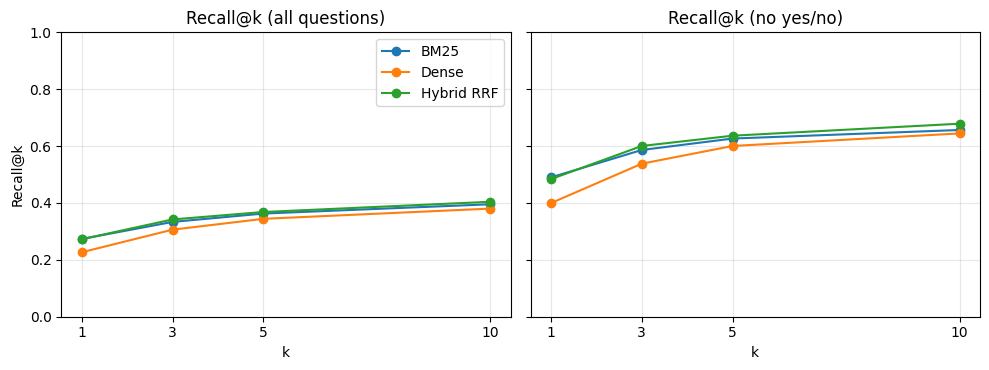

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (title, idx) in zip(axes, [('all questions', range(len(questions))), ('no yes/no', keep)]):
    for name, ranked in [('BM25', bm25_ranked), ('Dense', dense_ranked), ('Hybrid RRF', hybrid_ranked)]:
        ax.plot(KS, [recall_at_k(sub(ranked, idx), sub(answers, idx), k) for k in KS], marker='o', label=name)
    ax.set_title(f'Recall@k ({title})'); ax.set_xlabel('k'); ax.set_xticks(KS); ax.grid(alpha=.3)
axes[0].set_ylabel('Recall@k'); axes[0].set_ylim(0, 1); axes[0].legend()
plt.tight_layout()
plt.savefig(f'{OUT}/task3_recall_compare.png', dpi=150, bbox_inches='tight'); plt.show()

## 8. Groundedness check
### 8.1 Lexical overlap between an answer and its passages
For each Task 2 answer we take its content words (words that are not stop-words) and measure what fraction of them appears in each of the five passages it was generated from. We use exactly the 200-token text the LLM saw. The best passage gives the score:
- overlap = 1.0: every content word of the answer occurs in one retrieved passage (well supported);
- overlap = 0.0: none of its words occur in the evidence (possibly produced from the model's own knowledge).

**Answers that are just "yes" or "no" are excluded** from the check, and never abstained on, because these words almost never appear in passages. We decide this from the *prediction*, not the gold answer, because at answer time the system only knows its own output.

In [11]:
def overlap_score(answer, passage_texts):
    a = content_words(answer) or set(normalize_answer(answer).split())
    if not a:
        return 0.0
    return max(len(a & set(normalize_answer(p).split())) / len(a) for p in passage_texts)

def groundedness_frame(preds, ranked):
    rows = []
    for i, (p, ids) in enumerate(zip(preds, ranked)):
        seen = [passage_text(pid) for pid in ids[:TOP_K]]   # the 200-token text the LLM saw (cached)
        rows.append({'question': questions[i], 'gold': answers[i], 'pred': p,
                     'overlap': overlap_score(p, seen),
                     'F1': f1_score(p, answers[i]), 'EM': exact_match(p, answers[i]),
                     'yes_no': is_yes_no_prediction(p)})      # yes/no PREDICTION -> not checked
    df = pd.DataFrame(rows)
    df['correct'] = df['F1'] >= CORRECT_F1
    return df

ground = groundedness_frame(task2_preds, dense_ranked)
g = ground[~ground['yes_no']].copy()             # the check is applied to these answers
g['grounded'] = g['overlap'] >= THRESH
print(f'answers checked: {len(g)} | excluded yes/no answers: {int(ground.yes_no.sum())} '
      f'(of which {int((ground.yes_no & ~ground.gold.map(is_yes_no)).sum())} answer a factual question)')
g.head()

answers checked: 481 | excluded yes/no answers: 437 (of which 20 answer a factual question)


,question,gold,pred,overlap,F1,EM,yes_no,correct,grounded
3,How many long was Lincoln's formal education?,18 months,18 months,1.0,1.000000,1.0,False,True,True
4,When did Lincoln begin his political career?,1832,1832,1.0,1.000000,1.0,False,True,True
5,What did The Legal Tender Act of 1862 establish?,"the United States Note, the first paper curren...",United States Note,1.0,0.461538,0.0,False,False,True
6,Who suggested Lincoln grow a beard?,11-year-old Grace Bedell,Grace Bedell,1.0,0.800000,0.0,False,True,True
7,When did the Gettysburg address argue that Ame...,1776,1776,1.0,1.000000,1.0,False,True,True


### 8.2 How well does the check work?
We treat the check as a classifier: a high overlap predicts "correct", and a low overlap predicts "likely ungrounded or wrong" (flagged). We report:
- **correct answers with high overlap:** how often good answers pass the check;
- **incorrect answers with low overlap:** how often bad answers are caught;
- **groundedness-check accuracy:** the fraction of answers where the check agrees with correctness;
- **balanced accuracy:** the average of the first two, which is fairer when correct and incorrect answers are unbalanced;
- **majority baseline:** the accuracy of a check that never flags anything.

We also show the 2×2 table and a histogram of the overlap scores.

In [12]:
def check_report(df, name, thresh=THRESH, label='correct'):
    grounded = df['overlap'] >= thresh
    ok = df[label].astype(bool)
    hi_correct = grounded[ok].mean()                 # correct answers WITH high overlap
    lo_wrong   = (~grounded[~ok]).mean()             # incorrect answers WITH low overlap
    return {'Answers': name, 'N': len(df), 'correct': int(ok.sum()), 'flagged': int((~grounded).sum()),
            'correct w/ high overlap': hi_correct, 'incorrect w/ low overlap': lo_wrong,
            'check accuracy': (grounded == ok).mean(),
            'balanced accuracy': (hi_correct + lo_wrong) / 2,
            'majority baseline': max(ok.mean(), 1 - ok.mean())}

ground_table = pd.DataFrame([
    check_report(g, 'Task 2 answers (correct = F1 >= 0.5)'),
    check_report(g.assign(correct_em=g['EM'] == 1), 'Task 2 answers (correct = EM)', label='correct_em'),
]).round(4)
display(ground_table)

# 2x2 table for the report
pd.crosstab(g['correct'].map({True: 'correct', False: 'incorrect'}),
            g['grounded'].map({True: 'high overlap', False: 'low overlap (flagged)'}), margins=True)

,Answers,N,correct,flagged,correct w/ high overlap,incorrect w/ low overlap,check accuracy,balanced accuracy,majority baseline
0,Task 2 answers (correct = F1 >= 0.5),481,263,35,0.9886,0.1468,0.6071,0.5677,0.5468
1,Task 2 answers (correct = EM),481,156,35,0.9872,0.1015,0.3888,0.5444,0.6757


grounded,high overlap,low overlap (flagged),All
correct,,,
correct,260,3,263
incorrect,186,32,218
All,446,35,481


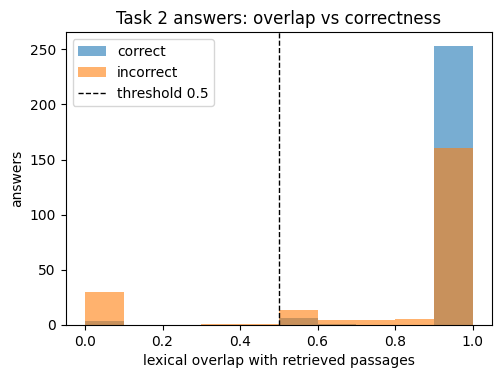

In [13]:
# Overlap distribution for correct vs incorrect answers
plt.figure(figsize=(5.5, 3.8))
bins = np.linspace(0, 1, 11)
plt.hist(g.loc[g.correct, 'overlap'], bins=bins, alpha=.6, label='correct')
plt.hist(g.loc[~g.correct, 'overlap'], bins=bins, alpha=.6, label='incorrect')
plt.axvline(THRESH, color='k', ls='--', lw=1, label=f'threshold {THRESH}')
plt.xlabel('lexical overlap with retrieved passages'); plt.ylabel('answers')
plt.title('Task 2 answers: overlap vs correctness'); plt.legend()
plt.savefig(f'{OUT}/task3_overlap_hist.png', dpi=150, bbox_inches='tight'); plt.show()

### 8.3 Abstaining on flagged answers, and the threshold sweep
To **abstain** means to answer *"I don't know"* instead of giving a flagged answer. A higher threshold keeps fewer answers (lower **coverage**), but the answers that are kept should be correct more often. In the "all questions" columns an abstention counts as wrong; yes/no predictions are never flagged.

,threshold,coverage,F1 on answered,check accuracy,EM all questions,F1 all questions
0,0.0,1.0000,0.5227,0.5468,0.5643,0.6710
1,0.1,0.9314,0.5556,0.6029,0.5621,0.6683
2,0.2,0.9314,0.5556,0.6029,0.5621,0.6683
3,0.3,0.9314,0.5556,0.6029,0.5621,0.6683
4,0.4,0.9293,0.5561,0.6050,0.5621,0.6680
5,0.5,0.9272,0.5574,0.6071,0.5621,0.6680
6,0.6,0.8898,0.5684,0.6195,0.5599,0.6621
7,0.7,0.8773,0.5742,0.6279,0.5599,0.6611
8,0.8,0.8690,0.5785,0.6362,0.5599,0.6606
9,0.9,0.8586,0.5835,0.6466,0.5599,0.6597


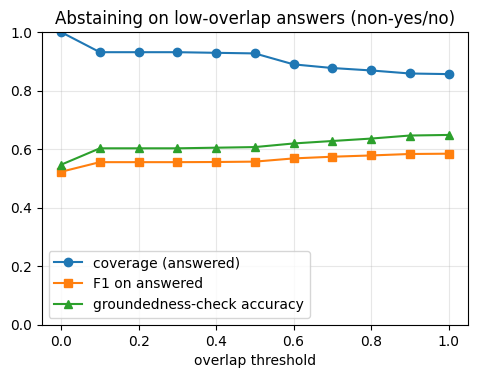

In [14]:
rows = []
for t in np.round(np.arange(0.0, 1.01, 0.1), 1):
    kept = g[g['overlap'] >= t]
    abstain_preds = ['' if (not ground.yes_no[i]) and ground.overlap[i] < t else ground.pred[i]
                     for i in range(len(ground))]
    rows.append({'threshold': t,
                 'coverage': len(kept) / len(g),                       # fraction still answered
                 'F1 on answered': kept['F1'].mean() if len(kept) else np.nan,
                 'check accuracy': ((g['overlap'] >= t) == g['correct']).mean(),
                 'EM all questions': np.mean([exact_match(p, a) for p, a in zip(abstain_preds, answers)]),
                 'F1 all questions': np.mean([f1_score(p, a) for p, a in zip(abstain_preds, answers)])})
sweep = pd.DataFrame(rows).round(4)
display(sweep)

plt.figure(figsize=(5.5, 3.8))
plt.plot(sweep['threshold'], sweep['coverage'], marker='o', label='coverage (answered)')
plt.plot(sweep['threshold'], sweep['F1 on answered'], marker='s', label='F1 on answered')
plt.plot(sweep['threshold'], sweep['check accuracy'], marker='^', label='groundedness-check accuracy')
plt.xlabel('overlap threshold'); plt.ylim(0, 1); plt.grid(alpha=.3); plt.legend()
plt.title('Abstaining on low-overlap answers (non-yes/no)')
plt.savefig(f'{OUT}/task3_threshold_sweep.png', dpi=150, bbox_inches='tight'); plt.show()

## 9. The check on the hybrid answers, and examples
We apply the same check to the hybrid answers, and list examples from three cells of the 2×2 table:
- wrong answers that pass the check;
- correct answers that are flagged;
- wrong answers that are caught.

In [15]:
gh = groundedness_frame(hybrid_preds, hybrid_ranked)
gh = gh[~gh['yes_no']].copy()
display(pd.DataFrame([check_report(g, 'Task 2 answers (dense top-5)'),
                      check_report(gh, 'Task 3 answers (hybrid top-5)')]).round(4))

pd.set_option('display.max_colwidth', 70)
cols = ['question', 'gold', 'pred', 'overlap']
print('Incorrect but HIGH overlap (copied words from the wrong place):')
display(g[(~g.correct) & (g.grounded)].head(5)[cols])
print('Correct but LOW overlap (flagged although right):')
display(g[(g.correct) & (~g.grounded)].head(5)[cols])
print('Incorrect and LOW overlap (caught by the check):')
display(g[(~g.correct) & (~g.grounded)].head(5)[cols])

,Answers,N,correct,flagged,correct w/ high overlap,incorrect w/ low overlap,check accuracy,balanced accuracy,majority baseline
0,Task 2 answers (dense top-5),481,263,35,0.9886,0.1468,0.6071,0.5677,0.5468
1,Task 3 answers (hybrid top-5),489,285,40,0.9719,0.1569,0.6319,0.5644,0.5828


Incorrect but HIGH overlap (copied words from the wrong place):


,question,gold,pred,overlap
5,What did The Legal Tender Act of 1862 establish?,"the United States Note, the first paper currency in United States ...",United States Note,1.0
12,Which county was Lincoln born in?,Hardin County,Kentucky,1.0
16,Who was the general in charge at the Battle of Antietam?,General McClellan,Lincoln,1.0
17,Why did Lincoln issue the Emancipation Proclamation?,To free slaves,To weaken the rebellion,1.0
28,Who graduated in ecclesiastical law at the early age of 20 and beg...,Amedeo Avogadro,He,1.0


Correct but LOW overlap (flagged although right):


,question,gold,pred,overlap
428,When did John Adams serve as Vice President?,1789-1797,1789-1797,0.0
554,Did Fillmore form a law partnership before or after he founded the...,Before.,before,0.0
893,When was Woodrow Wilson born?,"December 28, 1856",1856,0.0


Incorrect and LOW overlap (caught by the check):


,question,gold,pred,overlap
21,How old was Lincoln in 1816?,seven,7,0.0
54,What happened from 1730 to 1744?,He was professor of astronomy at Uppsala University,Not specified,0.0
55,What happened in 1745?,The scale was reversed,No information provided.,0.0
64,What are the similarities between beetles and grasshoppers?,mouthparts,None,0.0
138,What arrived in Britain?,The first Canadian Army units in WW II,Immigrants,0.0


## 10. Saving the results
`task3_results.json` contains:
- the fused rankings and the hybrid answers;
- all comparison and groundedness tables, the overlap scores and the threshold sweep;
- the dataset ids of the ranked passages and the configuration;
- SHA-256 hashes of the two input files, which records exactly which Task 1 and Task 2 results were combined.

In [16]:
if QUICK_TEST:
    print('QUICK_TEST is on - results NOT saved. Set QUICK_TEST = False and run all.')
else:
    with open(f'{OUT}/task3_results.json', 'w') as f:
        json.dump({'hybrid_ranked': hybrid_ranked,
                   'preds': hybrid_preds,
                   'comparison_all': compare_all.to_dict(orient='records'),
                   'comparison_no_yes_no': compare_fact.to_dict(orient='records'),
                   'groundedness': ground_table.to_dict(orient='records'),
                   'overlap_task2': ground['overlap'].tolist(),
                   'sweep': sweep.to_dict(orient='records'),
                   'passage_ids': passage_ids,           # dataset ids of the ranked positions
                   'config': {'rrf_c': RRF_C, 'top_k': TOP_K, 'threshold': THRESH,
                              'correct_f1': CORRECT_F1, 'llm': LLM_NAME, 'batch_size': BATCH_SIZE,
                              'dataset_revision': DATASET_REVISION,
                              'inputs': {os.path.basename(p): hashlib.sha256(open(p, 'rb').read()).hexdigest()
                                         for p in (task1_file, task2_file)}}}, f)
    print('saved', f'{OUT}/task3_results.json')

saved outputs/task3_results.json


## 11. Significance tests and further analysis
The differences between the systems are small, so we test them with exact paired McNemar tests on the same questions. We also look more closely at what the groundedness check misses and what it catches.

In [17]:
# Extra checks used in the discussion (run after the cells above)
import math

def mcnemar(a, b):
    # exact paired test: how often b is right where a is wrong, and the reverse
    up = sum(x == 0 and y == 1 for x, y in zip(a, b)); down = sum(x == 1 and y == 0 for x, y in zip(a, b))
    n, k = up + down, min(up, down)
    p = min(1.0, 2 * sum(math.comb(n, j) for j in range(k + 1)) / 2 ** n) if n else 1.0
    return up, down, p

# 1) Retrieval: paired comparison on factual questions
for k in [1, 5, 10]:
    hit = lambda R, i: float(first_hit_rank(R[i][:k], answers[i]) <= k)
    hb, hd, hh = ([hit(R, i) for i in keep] for R in (bm25_ranked, dense_ranked, hybrid_ranked))
    (u1, d1, p1), (u2, d2, p2) = mcnemar(hb, hh), mcnemar(hd, hh)
    print(f'1) R@{k:<2} hybrid vs BM25: +{u1}/-{d1} (p={p1:.3f}) | hybrid vs dense: +{u2}/-{d2} (p={p2:.3f})')
same_top = sum(h[0] in (b[0], d[0]) for h, b, d in zip(hybrid_ranked, bm25_ranked, dense_ranked))
print(f'   fused #1 passage is the BM25 #1 or the dense #1 for {same_top}/{len(questions)} questions')

# 2) Answers: paired comparison of EM, Task 2 vs hybrid
up, down, p = mcnemar([exact_match(task2_preds[i], answers[i]) for i in range(len(questions))],
                      [exact_match(hybrid_preds[i], answers[i]) for i in range(len(questions))])
print(f'2) EM hybrid vs Task 2: fixed {up}, broken {down} (p={p:.3f}); '
      f'answers changed: {sum(a != b for a, b in zip(task2_preds, hybrid_preds))}/{len(questions)}')

# 3) Groundedness: shape of the overlap scores and what the check misses / catches
ov = g['overlap']
print(f'3) overlap = 1.0: {(ov == 1).sum()}, = 0.0: {(ov == 0).sum()}, in between: {((ov > 0) & (ov < 1)).sum()} (of {len(g)})')
missed = g[(~g.correct) & (g.grounded)]
print(f'   incorrect but high overlap: {len(missed)}; partly right (0 < F1 < 0.5): {((missed.F1 > 0) & (missed.F1 < 0.5)).sum()}, '
      f'F1 = 0: {(missed.F1 == 0).sum()}')
flagged = g[~g.grounded]
refusal = flagged['pred'].str.contains(r'not (?:specified|provided|mentioned)|no information|^none\.?$', case=False)
numeric = flagged['pred'].str.fullmatch(r'[\d/.,\- ]+')
print(f'   flagged: {len(flagged)} -> model non-answers ("Not specified", "None", ...): {refusal.sum()}, '
      f'bare numbers: {numeric.sum()}, correct but flagged: {flagged.correct.sum()} {list(flagged[flagged.correct].pred)}')

1) R@1  hybrid vs BM25: +31/-34 (p=0.804) | hybrid vs dense: +63/-21 (p=0.000)
1) R@5  hybrid vs BM25: +20/-15 (p=0.500) | hybrid vs dense: +34/-16 (p=0.015)
1) R@10 hybrid vs BM25: +16/-5 (p=0.027) | hybrid vs dense: +30/-13 (p=0.014)
   fused #1 passage is the BM25 #1 or the dense #1 for 792/918 questions
2) EM hybrid vs Task 2: fixed 38, broken 31 (p=0.470); answers changed: 288/918
3) overlap = 1.0: 412, = 0.0: 33, in between: 36 (of 481)
   incorrect but high overlap: 186; partly right (0 < F1 < 0.5): 71, F1 = 0: 115
   flagged: 35 -> model non-answers ("Not specified", "None", ...): 8, bare numbers: 9, correct but flagged: 3 ['1789-1797', 'before', '1856']


## 12. Discussion

**Hybrid retrieval.** Fusing the BM25 and dense rankings with RRF (c = 60) gives the best Recall@k at k = 3, 5 and 10, both on all questions (R@10 0.404 vs 0.395 for BM25 and 0.380 for dense) and on the 498 factual questions:

| Factual questions | R@1 | R@3 | R@5 | R@10 |
|---|---|---|---|---|
| BM25 (Task 1) | 0.490 | 0.586 | 0.627 | 0.657 |
| Dense (Task 2) | 0.400 | 0.538 | 0.600 | 0.645 |
| Hybrid RRF (Task 3) | 0.484 | 0.600 | 0.637 | 0.679 |

At k = 1 fusion does not help (0.484 vs 0.490 for BM25; +31/−34 questions). The fused first passage is almost always one of the two retrievers' first passages (792 of 918 questions), so RRF mostly re-orders ranks 2–10.

In paired McNemar tests on the factual questions:
- **vs dense retrieval:** the gain is significant at every k (e.g. R@1 +63/−21, p < 0.001);
- **vs BM25:** the gain is significant only at k = 10 (+16/−5, p = 0.027), not at k = 5 (+20/−15, p = 0.50).

BM25 is already a strong retriever on this entity-heavy dataset. The hybrid's extra value lies in recovering answers that only the dense retriever finds.

**Effect on the answers.** With the same LLM, prompt, truncation, decoding and batch size as Task 2, only the retriever changes. EM rises from 0.564 to **0.572** and F1 from 0.671 to **0.684**; on the factual questions EM goes from 0.313 to 0.341 and F1 from 0.505 to 0.541. The gain is small and **not statistically significant**: 38 questions are fixed and 31 broken (p = 0.47), although 288 answers changed. Yes/no accuracy is slightly lower (0.864 vs 0.879). Better recall only partly reaches the answers, because many of the remaining errors come from the generator rather than from retrieval.

**Groundedness check.** On the 481 non-yes/no Task 2 answers, **98.9% of the correct answers have high overlap** (260 of 263), but only **14.7% of the incorrect answers have low overlap** (32 of 218). The check's accuracy is **0.607**, only a little above the 0.547 of never flagging anything (balanced accuracy 0.568). With exact match as the definition of correct, it is even worse than never flagging (0.389 vs 0.676).

The overlap score is almost binary: 412 of the 481 answers score exactly 1.0 and 33 score 0.0. The LLM nearly always copies words from the passages, so most errors are *grounded but wrong*:
- a span from the wrong place, such as *"Kentucky"* instead of *"Hardin County"*;
- or an answer that is only partly right (71 of the 186 incorrect, high-overlap answers have 0 < F1 < 0.5).

What the check does catch is real:
- 8 non-answers such as *"Not specified"* and *"No information provided."*;
- numbers the model computed or wrote as digits (*"7"* vs *"seven"*);
- a few invented answers (*"Immigrants"*).

Only 3 correct answers are flagged:
- *"1789-1797"*, because normalisation merges the two years into one token;
- *"before"*, because it is a stop-word;
- *"1856"* (Woodrow Wilson's birth year), which appears in none of the retrieved passages. This is a correct answer the model knew from memory, exactly the kind of ungrounded answer the check is meant to expose.

The hybrid answers show the same picture (accuracy 0.632 vs 0.583 for never flagging).

**Abstaining.** At threshold 0.5 the system still answers 92.7% of the checked questions, and F1 on those rises from 0.523 to 0.557. Overall EM, however, drops slightly (0.564 → 0.562), because the flagged answers were mostly wrong already and abstaining also removes a few correct ones. The threshold sweep peaks at 1.0 (check accuracy 0.649), but we chose that threshold on the test questions themselves, so it is an analysis rather than a tuned result.

**Limitations.** Recall@k is measured by answer-string matching, and "correct" is defined by an F1 threshold, so both depend on how the gold answers are phrased. The overlap check works on surface words only: it cannot recognise paraphrases, and it cannot tell whether a copied span actually answers the question.

**Conclusion.** Hybrid retrieval is a cheap and reliable improvement in recall, especially over dense retrieval and at larger k, but on this dataset it barely moves EM and F1. Lexical overlap is a useful warning sign for answers that do not come from the evidence (non-answers, invented, computed or remembered answers), which matches the hallucination motivation of the project. It cannot detect the most common failure, however: a fluent answer copied from the wrong place in the retrieved passages. Catching that would need a semantic check, for example entailment between passage, question and answer, rather than word overlap.

## 13. References
- G. V. Cormack, C. L. A. Clarke and S. Büttcher (2009). *Reciprocal Rank Fusion Outperforms Condorcet and Individual Rank Learning Methods.* SIGIR.
- P. Lewis, E. Perez, A. Piktus et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.* NeurIPS. arXiv:2005.11401
- S. Robertson and H. Zaragoza (2009). *The Probabilistic Relevance Framework: BM25 and Beyond.* Foundations and Trends in Information Retrieval.
- V. Karpukhin, B. Oğuz, S. Min et al. (2020). *Dense Passage Retrieval for Open-Domain Question Answering.* EMNLP.
- Z. Ji, N. Lee, R. Frieske et al. (2023). *Survey of Hallucination in Natural Language Generation.* ACM Computing Surveys.
- Q. McNemar (1947). *Note on the Sampling Error of the Difference between Correlated Proportions or Percentages.* Psychometrika.